In [2]:
# Import necessary libraries for data manipulation and visualization

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plots are displayed inline in the notebook
%matplotlib inline

In [ ]:
dataframe = pd.read_csv(r"amz_uk_price_prediction_dataset.csv")

dataframe = pd.DataFrame(dataframe) # Ensure it's a proper DataFrame object

# Create a backup copy of the original DataFrame
backup_dataframe = dataframe.copy()

In [4]:
# Separate numerical and categorical columns for easier analysis
# This allow us to apply numeric operations on numeric columns and categorical operations on text columns

numeric = dataframe.select_dtypes(include="number")
categorical = dataframe.select_dtypes(exclude="number")

# Display the first few rows to check the strcuture of the DataFrame
dataframe.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
# Check possible missing values

missing_values = pd.isnull(dataframe)
# Count missing values in each column
missing_counts = missing_values.sum()

# Count columns with missing values
columns_with_missing = missing_counts[missing_counts > 0].count()

# Check if all columns have missing values
all_columns_missing = missing_counts.all()

# Calculate the total number of missing values
total_missing_values = missing_counts.sum()

# Display the results
print("Missing Values in Each Column:\n", missing_counts)
print("\nNumber of Columns with Missing Values:", columns_with_missing)
print("All Columns Have Missing Values:", all_columns_missing)
print("\nTotal Missing Values in the DataFrame:", total_missing_values)

Missing Values in Each Column:
 uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

Number of Columns with Missing Values: 0
All Columns Have Missing Values: False

Total Missing Values in the DataFrame: 0


In [6]:
categorical.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [34]:
#Create a crosstab between the product `category` and the `isBestSeller` status.
is_best_seller= categorical["isBestSeller"]
category = categorical["category"]

ctab_cate_isbest= pd.crosstab(category, is_best_seller )
ctab_cate_isbest.columns = ["Not_BestSeller", "BestSeller"]
ctab_cate_isbest

#The ratio between best sellers or not is very small, most books are not best sellers



,Not_BestSeller,BestSeller
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [35]:
from scipy.stats import chi2_contingency
_, chi2_pvalue, _, _ = chi2_contingency(ctab_cate_isbest)

print(f"The P value is: {chi2_pvalue}\n")

if chi2_pvalue < 0.05:
    print("There is a significant association between category and isBestSeller")
else:
    print("There is not enough evidence to conclude a significant association between category and isBestSeller.")


The P value is: 0.0

There is a significant association between category and isBestSeller


In [36]:
from scipy.stats.contingency import association

def calculate_strength_association(df):
    number = association(df, method="cramer")
    number_round = round(number, 2)

    if 0 < number_round <= 0.10:
        strength = "negligible or very weak"
    elif number_round <= 0.20:
        strength = "weak"
    elif number_round <= 0.30:
        strength = "moderate"
    elif number_round <= 0.50:
        strength = "strong"
    elif number_round > 0.50:
        strength = "very strong"
    else:
        strength = "Not possible to calculate"
    
    return f"The association is {strength}, the association value is: {number_round}"

print(calculate_strength_association(ctab_cate_isbest))


The association is weak, the association value is: 0.12


## Analysis
Although the Chi-square test indicates a statistically significant relationship between product category and best-seller status, the Cramér’s V value reveals that the strength of this association is weak.

This means that, while there is evidence that category and best-seller status are not entirely independent, the practical impact of category on a product becoming a best-seller is minimal.

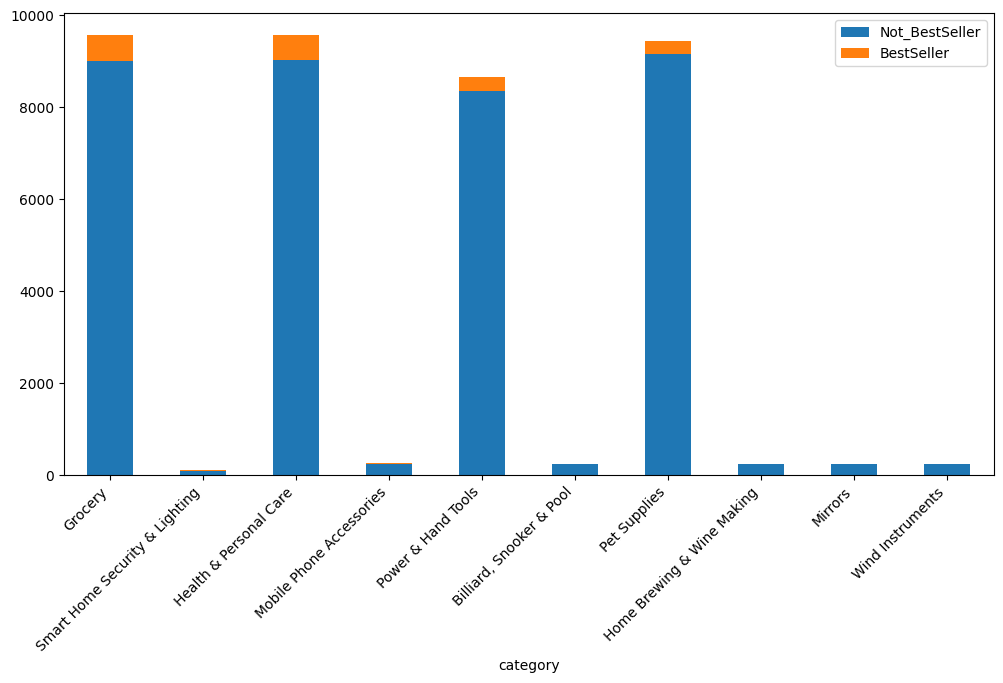

In [ ]:

ctab_cate_isbest["Total"] = ctab_cate_isbest["Not_BestSeller"] + ctab_cate_isbest["BestSeller"]
ctab_cate_isbest["Prop_BestSeller"] = ctab_cate_isbest["BestSeller"] / ctab_cate_isbest["Total"]

ctab_cate_isbest_sorted = ctab_cate_isbest.sort_values(by="Prop_BestSeller", ascending=False)

ctab_cate_isbest_sorted

top_categories = [
    "Grocery", "Smart Home Security & Lighting", "Health & Personal Care",
    "Mobile Phone Accessories", "Power & Hand Tools", "Billiard, Snooker & Pool",
    "Pet Supplies", "Home Brewing & Wine Making", "Mirrors", "Wind Instruments"
]

ctab_cate_isbest_sorted.loc[top_categories, ["Not_BestSeller","BestSeller"]].plot(
    kind='bar', stacked=True, figsize=(12,6)
)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of Products")
plt.title("Best Seller vs Not Best Seller in Top Categories")
plt.tight_layout()
plt.show()




## Analysis

General observation: The majority of products are not bestsellers, so bestsellers represent only a small fraction of the total products in each category.

Specific insight: The categories with the highest proportion of bestsellers are those related to everyday consumer purchases, such as Grocery and Health & Personal Care.

Practical interpretation: This suggests that, although many products exist on Amazon, only a few categories have a notable concentration of products that achieve best-seller status, which could guide marketing decisions or inventory strategy.

In [ ]:
# Calculate Interquartile Range (IQR = Q3 - Q1) 
# Represents the middle 50% of ratings

Q1 = numeric['price'].quantile(0.25)
Q3 = numeric['price'].quantile(0.75)
IQR = Q3 - Q1

inferior_limit = Q1 - 1.5 * IQR
superior_limit = Q3 + 1.5 * IQR

filtered_price = dataframe[(dataframe["price"] >= inferior_limit) & (dataframe["price"] <= superior_limit)]
filtered_price.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443645,2828588,B0BQMXJPP5,Helmet Ponytail Pigtails Twist Braids Hair wit...,0.0,0,19.99,False,0,Motorbike Clothing
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing


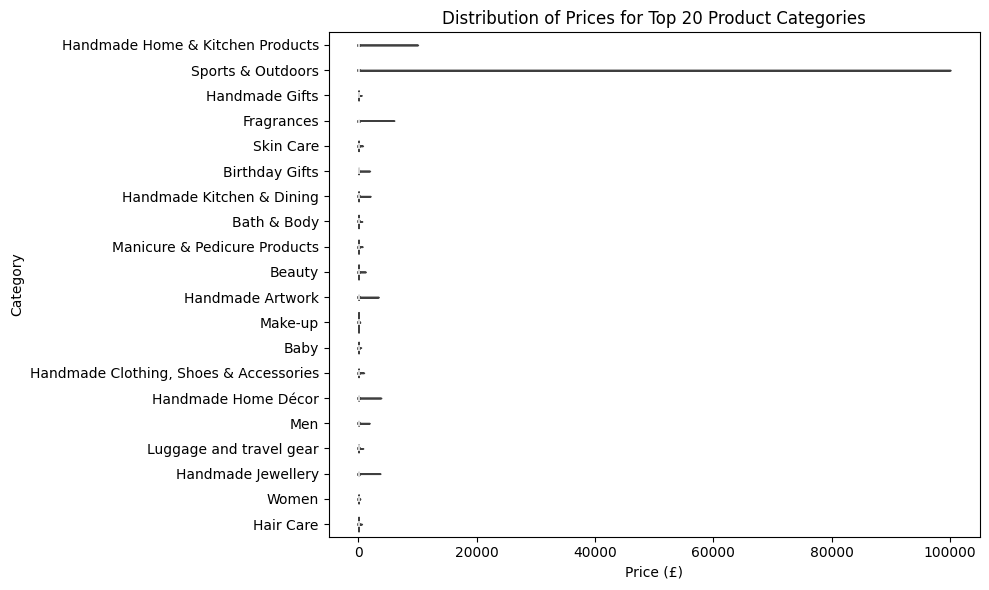

In [ ]:
top_20_categories = dataframe['category'].value_counts().head(20).index
filtered_top20 = dataframe[(dataframe['category'].isin(top_20_categories))]

df_top20 = filtered_price [filtered_price ['category'].isin(top_20_categories)]

plt.figure(figsize=(10, 8))
sns.violinplot(data=df_top20, x='price', y='category', palette="coolwarm", hue='category')
plt.title("Price Distribution by Top 20 Categories")
plt.show()



## Analysis

Most product categories have low to mid-range prices.
A few categories have highly variable pricing, showing the presence of premium products.
This suggests that Amazon UK has a high volume of affordable products, with selective categories catering to high-end buyers.

In [25]:
mean_rating = dataframe['stars'].mean()
median_rating = dataframe['stars'].median()
mode_rating = dataframe['stars'].mode()[0]


In [26]:
var_rating = dataframe["stars"].var()
std_rating = dataframe["stars"].std()
iqr_rating = dataframe["stars"].quantile(0.75) - dataframe["stars"].quantile(0.25)


In [27]:
# Shape of the Distribution: Skewness and Kurtosis


# Calculate skewness: measures the asymmetry of the ratings distribution
skewness_stars = round(float(numeric["stars"].skew()), 2)

# Calculate kurtosis: measures the "tailedness" of the distribution

# Excess kurtosis = 0 corresponds to a normal distribution
kurtosis_stars = numeric['stars'].kurtosis()  

# Print skewness and kurtosis values
print(f"The skewness for the stars column is: {skewness_stars}")
print(f"The kurtosis for the stars column is: {kurtosis_stars:.2f}")

# Interpretation based on skewness
if skewness_stars == 0:
    print(" The distribution is perfectly symmetrical, resembling a normal distribution.")
elif skewness_stars > 0:
    print("""The distribution is **positively skewed** (right-skewed).
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.""")
elif skewness_stars < 0:
    print(""" The distribution is **negatively skewed** (left-skewed).  
        - Longer tail on the **left** side.  
        - The bulk of the data is concentrated on the **right**.""")
        
# Note:
# - Positive skew means most products have low ratings, with few high ratings.
# - Negative skew would indicate most products have high ratings, with few low ratings.
# - Kurtosis indicates how heavy or light the tails are compared to a normal distribution.


The skewness for the stars column is: 0.08
The kurtosis for the stars column is: -1.93
The distribution is **positively skewed** (right-skewed).
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.


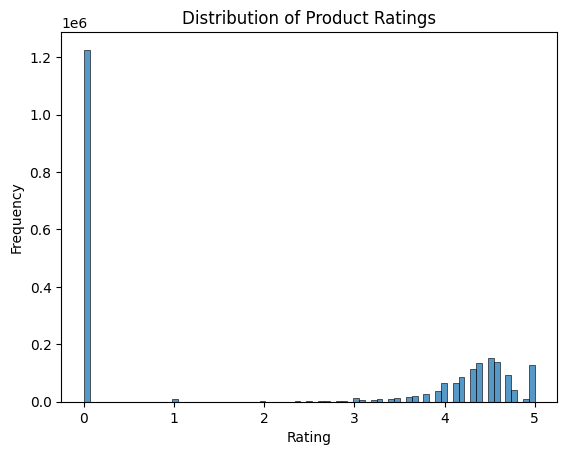

In [28]:
sns.histplot(numeric["stars"], bins="auto")
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()


## Analysis:

Most products have a rating of 0, meaning they have not yet been reviewed. Among products that have ratings, the distribution is slightly right-skewed (skewness = 0.08) and relatively flat (kurtosis = -1.93). Ratings are mostly concentrated between 4 and 5 stars, with few products receiving low ratings, indicating that reviewed products tend to be positively rated.